Atributos:
  C: 0.00065
  bit_depth: 8
  cam_pixel_size_um: 3.75
  expo: 0.00010999890001099989s
  lamb: 6.33e-07
  magnification: 1.386002559863437
  step_size_nm: 200
  z: 0

Datasets:
  background: shape=(5, 960, 1280), dtype=uint8
  images: shape=(21, 960, 1280), dtype=uint8
  index: shape=(21, 2), dtype=int64


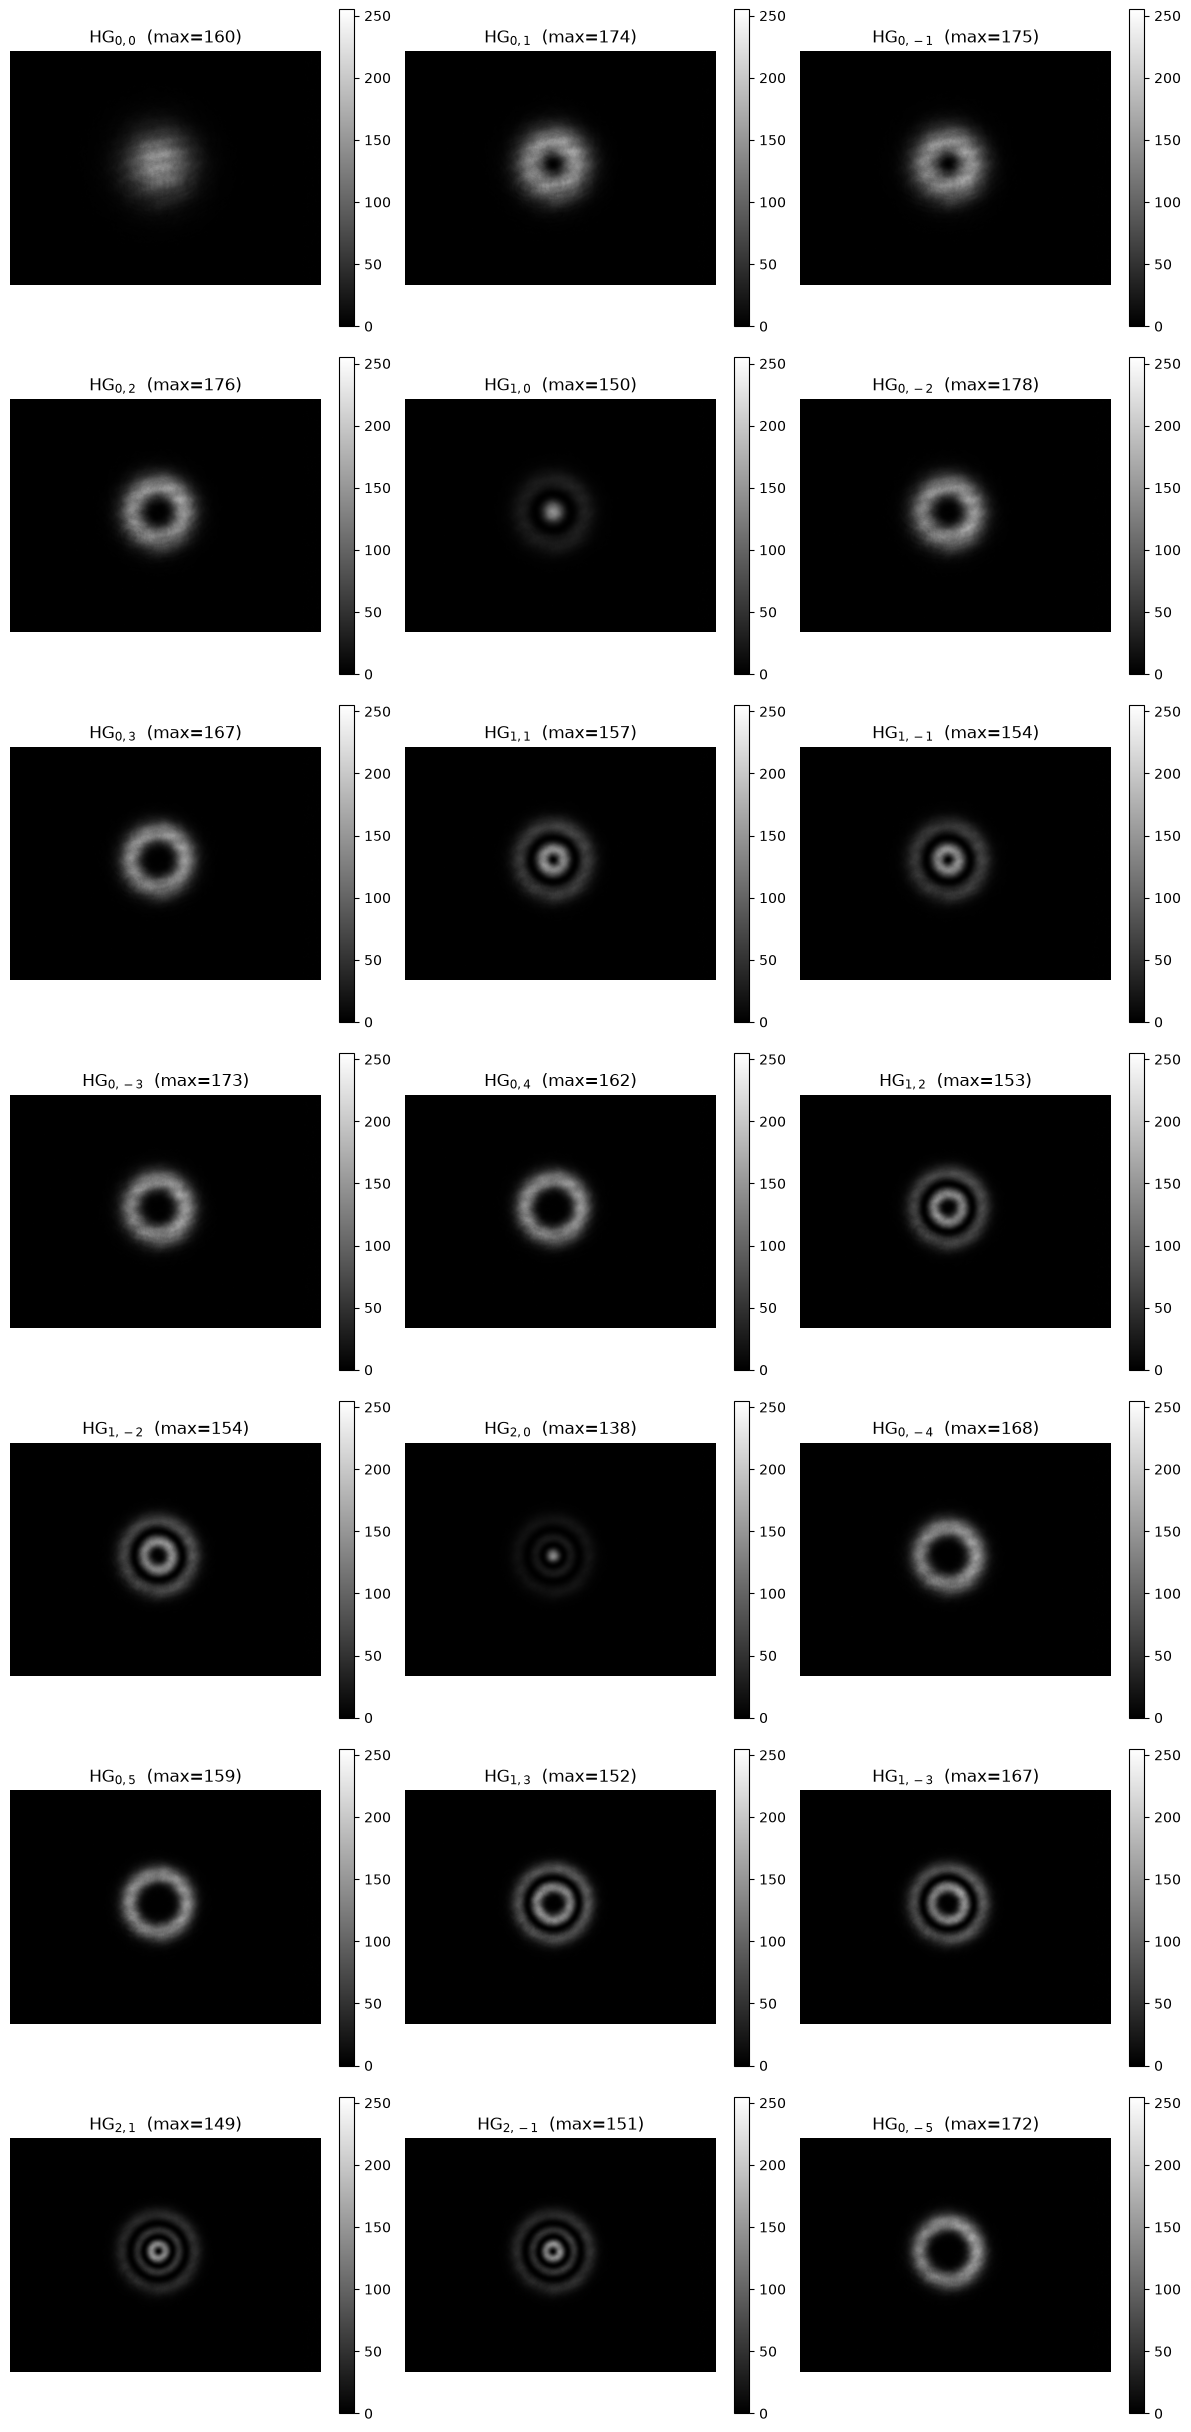

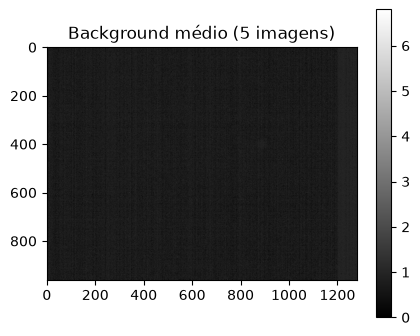

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

FOLDER = "Amostras_10_2026_sample_plane/"  # ajuste para sua pasta

with h5py.File(f"{FOLDER}data_LG_fix.h5", "r") as file:
    # Atributos
    print("Atributos:")
    for key, value in file.attrs.items():
        print(f"  {key}: {value}")

    print("\nDatasets:")
    for name, ds in file.items():
        print(f"  {name}: shape={ds.shape}, dtype={ds.dtype}")

    images = file["images"][:]
    index = file["index"][:]
    background = file["background"][:]

# Imagens adquiridas
n_img = len(images)
ncols = 3
nrows = int(np.ceil(n_img / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.5 * nrows),
                         squeeze=False)
for ax, img, (n, m) in zip(axes.ravel(), images, index):
    im = ax.imshow(img, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"HG$_{{{n},{m}}}$  (max={img.max()})")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046)

for ax in axes.ravel()[n_img:]:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Background médio (opcional)
plt.figure(figsize=(5, 4))
plt.imshow(background.mean(axis=0), cmap="gray")
plt.title(f"Background médio ({len(background)} imagens)")
plt.colorbar()
plt.show()